### Zollstock – Lösung Schritt für Schritt

*32. Bundeswettbewerb Informatik (2013), 1. Runde, Junioraufgabe 2*

Die Auszubildende Raluca hat einen 2 m langen Zollstock, der aus zehn gleich langen starren Segmenten besteht und an einem Ende
ein Loch zum Aufhängen hat. Am Ende der Arbeitszeit hat sie es immer sehr eilig: Der Zollstock wird rasch irgendwie so
zusammengefaltet, dass er in Ralucas Stoffbeutel passt. Dieser ist 50 cm lang und kann damit gerade zwei Segmente des
Zollstocks in Verlängerung voneinander aufnehmen; aber er ist zu schmal für ein „quer stehendes“ Zollstocksegment.

Als Ralucas Verlobter diese lustige Gewohnheit bemerkt, sagt er zu ihr: „Morgen bist du schon zwei Monate im Betrieb.
Bestimmt hast du den Zollstock an zwei Tagen in genau derselben Weise gefaltet“. Aber Raluca erwidert: „Das muss nicht sein.
Es ist durchaus möglich, dass sich bisher keine Faltung wiederholt hat“.

#### Junioraufgabe 2

Finde heraus, wer von den beiden recht hat, und beschreibe deine Vorgehensweise.

Beispieldaten gibt es zu dieser Aufgabe nicht.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Modellieren:** Das Problem wird zu einer Frage über Zahlen: Wie viele **verschiedene gültige** Faltungen gibt es? Ist diese Zahl kleiner als die Anzahl der Tage, muss sich eine Faltung wiederholt haben
  (**Schubfachprinzip**: Bei mehr Tagen als Möglichkeiten muss sich eine Möglichkeit wiederholen).
- **Alle Möglichkeiten erzeugen (Brute Force):** Jedes der 9 Gelenke ist gefaltet oder nicht, das sind 2⁹ = 512 Kombinationen. Man kann sie als Zeichenketten aus `0` und `1` schreiben und alle durchgehen.
- **Simulation:** Für jede Kombination läuft man den Zollstock Segment für Segment ab und merkt sich, wo die Segmente liegen. Wenn ein Gelenk gefaltet ist, **kehrt** die Richtung um.
- **Bedingungen prüfen:** Der Beutel ist nur 2 Segmente lang. Der gefaltete Zollstock darf also höchstens 2 Segmente lang sein.

**Nützliche Funktionen und Bibliotheken**
- `format(zahl, '09b')` schreibt eine Zahl als Binärzahl mit 9 Stellen, `itertools.product('01', repeat=9)` liefert alle 512 Kombinationen, `min`, `max`, `count`
- Zum Zeichnen: `matplotlib.pyplot` (optional)

## Die Idee

**Das Modell.** Der Zollstock hat 10 Segmente und 9 Gelenke. Jedes Gelenk ist entweder **gestreckt** (`0`) oder **gefaltet** (`1`). Eine Faltung ist also eine Folge aus 9 Ziffern, zum Beispiel `100000000` (nur das erste Gelenk am Loch gefaltet) oder `000000001`
(nur das letzte). Wegen des Lochs zum Aufhängen unterscheidet man die beiden Enden: `100000000` und `000000001` sind **verschieden**. Dagegen ist egal, ob man links herum oder rechts herum faltet. Es gibt also 2⁹ = **512** Möglichkeiten.

**Gültigkeit.** Nicht jede Faltung passt in den Beutel (50 cm, das sind 2 Segmente in einer Reihe). Wir stellen uns den gefalteten Zollstock als Linie vor und laufen von Segment zu Segment: Wir beginnen bei Position 0, das erste Segment
reicht bis Position 1. Ist das nächste Gelenk gestreckt, geht es in dieselbe Richtung weiter, ist es gefaltet, in die Gegenrichtung (zurück). Dabei merken wir uns die kleinste und die größte Position. Die Faltung ist **gültig**,
wenn `größte − kleinste ≤ 2` gilt. Sonst ragt der Zollstock über die 2 Segmente hinaus.

**Antwort.** Es gibt `G` gültige Faltungen. Wenn Raluca an **mehr Tagen** den Zollstock faltet als `G`, muss sich eine Faltung wiederholt haben (Schubfachprinzip), und ihr Verlobter hat recht. Bei **höchstens `G` Tagen**
kann es sein, dass sich noch keine wiederholt hat, und Raluca kann recht haben.

## Schritt 1: Ist eine Faltung gültig?

`ist_gueltig(faltung)` bekommt die Zeichenkette aus 9 Ziffern. Wir laufen den Zollstock ab:

- `position` ist das Ende des aktuellen Segments auf der Linie, am Anfang 1 (das erste Segment reicht von 0 bis 1).
- `richtung` ist `+1` (nach rechts) oder `-1` (nach links). Am Anfang `+1`.
- Für jedes Gelenk: Ist es gefaltet (`'1'`), kehren wir die Richtung um (`richtung = -richtung`). Dann geht das nächste Segment um 1 weiter: `position = position + richtung`. Wir merken uns die kleinste und die größte Position.

Am Ende prüfen wir, ob der gefaltete Zollstock höchstens 2 lang ist.

In [ ]:
def ist_gueltig(faltung):
    position = 1                    # Ende des ersten Segments (es liegt zwischen 0 und 1)
    richtung = 1
    kleinste = 0
    groesste = 1
    for gelenk in faltung:
        if gelenk == '1':
            richtung = -richtung    # gefaltet: das nächste Segment geht zurück
        position = position + richtung
        if position < kleinste:
            kleinste = position
        if position > groesste:
            groesste = position
    return groesste - kleinste <= 2


for faltung in ['000000000', '100000000', '000000001', '101010101', '011011011', '110110110', '100000001']:
    print(faltung, ist_gueltig(faltung))

000000000 False
100000000 False
000000001 False
101010101 True
011011011 False
110110110 False
100000001 False


`000000000` ist ein gerader Stab (zu lang), `100000000` hat zwei Segmente übereinander und dann acht in einer Reihe, also auch zu lang. `101010101` ist eine Ziehharmonika und passt.
`011011011` hat nie drei Segmente in einer Reihe, ist aber 80 cm lang und passt deshalb **nicht** (dieser Fall wird gern übersehen).

## Schritt 2: Alle 512 Faltungen durchgehen

`itertools.product('01', repeat=9)` liefert alle Folgen aus 9 Zeichen, die jeweils `'0'` oder `'1'` sind. Mit `''.join(...)` machen wir daraus eine Zeichenkette.
Wir sammeln die gültigen Faltungen in einer Liste.

In [ ]:
import itertools


def alle_gueltigen():
    liste = []
    for folge in itertools.product('01', repeat=9):
        faltung = ''.join(folge)
        if ist_gueltig(faltung):
            liste.append(faltung)
    return liste


gueltige = alle_gueltigen()
print('Mögliche Faltungen insgesamt:', 2 ** 9)
print('Davon gültig:', len(gueltige))

Mögliche Faltungen insgesamt: 512
Davon gültig: 47


## Schritt 3: Wer hat recht?

Die Aufgabe nennt „zwei Monate“. Ein Monat hat etwa 20 Arbeitstage, also sind es etwa **40 Arbeitstage**. (Falten ist nur an Arbeitstagen nötig, denn nur dann hat Raluca den Zollstock im Beutel.)
Mit 47 gültigen Faltungen und 40 Tagen ist es gut möglich, dass keine Faltung doppelt vorkam: Raluca kann recht haben.

Anders sieht es aus, wenn man **jeden Kalendertag** zählt (etwa 61 bis 62 Tage in zwei Monaten): Dann gäbe es mehr Tage als Faltungen, und eine Faltung hätte sich wiederholen **müssen**.
Das Programm rechnet für verschiedene Tageszahlen nach.

In [ ]:
anzahl = len(gueltige)
for tage in [30, 40, 47, 48, 62]:
    if tage > anzahl:
        urteil = f'Verlobter hat recht: bei {tage} Tagen und nur {anzahl} Faltungen muss eine Faltung doppelt vorkommen'
    else:
        urteil = f'Raluca kann recht haben: {tage} Tage, {anzahl} Faltungen, es muss sich keine wiederholt haben'
    print(f'{tage:2} Tage: {urteil}')

30 Tage: Raluca kann recht haben: 30 Tage, 47 Faltungen, es muss sich keine wiederholt haben
40 Tage: Raluca kann recht haben: 40 Tage, 47 Faltungen, es muss sich keine wiederholt haben
47 Tage: Raluca kann recht haben: 47 Tage, 47 Faltungen, es muss sich keine wiederholt haben
48 Tage: Verlobter hat recht: bei 48 Tagen und nur 47 Faltungen muss eine Faltung doppelt vorkommen
62 Tage: Verlobter hat recht: bei 62 Tagen und nur 47 Faltungen muss eine Faltung doppelt vorkommen


**Ergebnis:** Es gibt 47 gültige Faltungen. Bei etwa 40 Arbeitstagen in zwei Monaten kann Raluca recht haben. Ab dem 48. Tag müsste sich eine Faltung wiederholt haben, bei 62 Kalendertagen sicher.
Wir antworten also: **Es kommt auf die Zahl der Tage an. Bei etwa 40 Arbeitstagen kann Raluca recht haben, bei 48 oder mehr Faltungen an verschiedenen Tagen muss ihr Verlobter recht haben.**

## Für Neugierige: Wie sehen die gültigen Faltungen aus?

Wir zeichnen einige der gültigen Faltungen. Jedes Segment ist eine Strecke; beim Zeichnen schieben wir die Segmente übereinander in die Höhe, damit man sie unterscheiden kann.
Das Segment 1 (mit dem Loch) ist rot markiert.

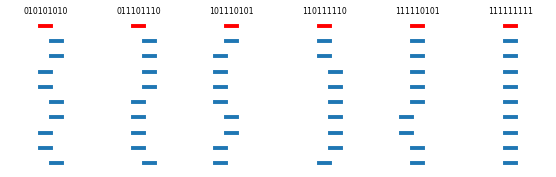

In [ ]:
import matplotlib.pyplot as plt


def segmente(faltung):
    # Liefert für jedes Segment (von, bis) auf der Linie
    liste = []
    anfang = 0
    richtung = 1
    for i in range(10):
        if i > 0 and faltung[i - 1] == '1':
            richtung = -richtung
        liste.append((anfang, anfang + richtung))
        anfang = anfang + richtung
    return liste


def zeichne(faltung, achse):
    for i, (von, bis) in enumerate(segmente(faltung)):
        farbe = 'red' if i == 0 else 'tab:blue'
        achse.plot([von, bis], [10 - i, 10 - i], color=farbe, linewidth=4)
    achse.set_xlim(-3, 4)
    achse.set_title(faltung, fontsize=8)
    achse.axis('off')


auswahl = [gueltige[0], gueltige[10], gueltige[20], gueltige[30], gueltige[40], gueltige[46]]
bild, achsen = plt.subplots(1, 6, figsize=(10, 2.8))
for faltung, achse in zip(auswahl, achsen):
    zeichne(faltung, achse)
plt.show()

Man erkennt, dass die gültigen Faltungen wie eine Ziehharmonika hin und her laufen, aber nie weiter als zwei Segmente. In keiner gültigen Faltung stehen zwei gestreckte Gelenke (`00`) direkt hintereinander,
sonst lägen drei Segmente in einer Reihe. Das ist eine notwendige, aber nicht hinreichende Bedingung (`011011011` hat sie und ist trotzdem ungültig).

In [ ]:
print('Die gültigen Faltungen:')
for i in range(0, len(gueltige), 8):
    print(' '.join(gueltige[i:i + 8]))

Die gültigen Faltungen:
010101010 010101011 010101110 010101111 010111010 010111011 010111110 010111111
011101010 011101011 011101110 011101111 011111010 011111011 011111110 011111111
101010101 101010111 101011101 101011111 101110101 101110111 101111101 101111111
110101010 110101011 110101110 110101111 110111010 110111011 110111110 110111111
111010101 111010111 111011101 111011111 111101010 111101011 111101110 111101111
111110101 111110111 111111010 111111011 111111101 111111110 111111111
